# NB10 -- Multi-Functor Composition in RELIC

This notebook inspects a hydrology dependency graph with the
**DependencyGraphResolver** and probes the scientific kernels separately.
The response probes below do not register this five-Functor set with
RELICSimulator: bucket, surface runoff, and vertical percolation expose
overlapping alternative closures and must not be treated as one closed budget.  We instantiate five
concrete hydrosphere Functors, all `TransportMechanismFunctor` subclasses:

| Functor | Class | State and flux outputs (non-diagnostic) |
|---------|-------|-------------|
| `bucket_soil_moisture` | `BucketSoilMoisture` | `soil_moisture`, `surface_runoff_flux`, `drainage_flux` |
| `penman_monteith_et` | `PenmanMonteithET` | `evapotranspiration_flux`, `latent_heat_flux`, `canopy_storage` |
| `vertical_percolation_transport` | `VerticalPercolationTransport` | `drainage_flux` |
| `surface_runoff` | `SurfaceRunoff` | `surface_runoff_flux`, `infiltration_flux` |
| `subsurface_runoff` | `SubsurfaceRunoff` | `subsurface_runoff_flux`, `groundwater_storage` |

and verify the theoretical guarantees from the **RELIC Coertheory** document.

## Architecture Anchor

This notebook is aligned with `docs\source\architecture_overview.md` and the relevant theory/API pages under `docs\source`.
All computations below are intended to use actual RELIC functors, the actual simulator or orchestration layer, and real validation pathways rather than notebook-defined pseudo-process equations.


## 1. Theoretical Foundation

### Theorem 3.6.1 -- DAG Executability (Kahn 1962)

Let $\mathcal{G} = (V, E)$ be the dependency graph induced by a set of
registered Functors $\{F_i\}_{i=1}^n$.  A topological ordering
$\sigma : V \to \{1, \dots, n\}$ exists if and only if $\mathcal{G}$ is a
**Directed Acyclic Graph** (DAG).

$$
\exists\,\sigma \;\text{s.t.}\;\forall\,(u \to v) \in E:\;
  \sigma(u) < \sigma(v)
\;\;\Longleftrightarrow\;\;
\mathcal{G}\;\text{is acyclic.}
$$

The DependencyGraphResolver implements **Kahn's algorithm** with $O(|V|+|E|)$
complexity.  
*Reference:* Kahn, A. B. (1962). "Topological sorting of large networks."
Communications of the ACM.

### Contractual Composition and Typed State Commits

A DAG provides a dependency-compatible order, but metadata and acyclicity do
not by themselves make arbitrary outputs additive. RELIC also requires
compatible writer permissions, units, time bases, and update modes.
`REPLACE` supplies a new value, an integrated `ACCUMULATE` amount adds once,
and a per-second rate is integrated over its actual commit interval.

For compatible amount increments alone,

$$
x_{k+1}=x_k+\sum_i\Delta x_i.
$$

This identity must not be applied to replacement values or competing closures.
The standalone kernel probes in this notebook report their declared outputs;
they do not certify a simulator-wide committed composition.


### Corollary 2.5.5 -- Topological Fingerprint

The **topological fingerprint** of the dependency graph is a tuple
$(|V|,\; |E|,\; p)$ where $p$ is the number of parallel execution groups
(layers of independent Functors revealed by Kahn's algorithm):

$$
\sigma(\mathcal{G}) = \bigl(|V|,\; |E|,\; p\bigr).
$$

If the fingerprint changes between model versions, the execution schedule has
structurally changed, which is essential for reproducibility audits.

### Corollary 3.6.5 -- Increment Attribution

For any state variable $x$ modified during a simulation step:

$$
\Delta x = \sum_{i \in \mathcal{P}(x)} \Delta x_i,
$$

where $\mathcal{P}(x)$ contains compatible contributors of integrated amounts
actually committed to $x$. Declaring an output name alone does not make it
an additive contributor. Replacement values and rates retain their own semantics.

In [1]:
# --- Environment guard for notebook execution ---
import os
import sys
import warnings
from pathlib import Path

os.environ['KMP_DUPLICATE_LIB_OK'] = 'TRUE'
warnings.filterwarnings('ignore', category=FutureWarning, module=r'torch\\cuda')
warnings.filterwarnings('ignore', message=r'The pynvml package is deprecated.*')

import torch


def locate_project_root() -> Path:
    fallback_candidates = [
        Path.cwd(),
        *Path.cwd().parents,
        Path(os.environ.get('RELIC_PROJECT_ROOT', Path.cwd())).resolve(),
    ]
    checked = []
    for candidate in fallback_candidates:
        resolved = candidate.resolve()
        if resolved in checked:
            continue
        checked.append(resolved)
        if (resolved / 'relic').is_dir() and (resolved / 'docs' / 'source' / 'architecture_overview.md').is_file():
            return resolved
    raise FileNotFoundError('Could not locate RELIC project root from the current notebook context.')


PROJECT_ROOT = locate_project_root()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

print(f'Project root : {PROJECT_ROOT}')
print(f'PyTorch      : {torch.__version__}')

Project root : <RELIC_ROOT>
PyTorch      : 2.13.0+cu130


In [2]:
import torch
import matplotlib.pyplot as plt

from relic.core.dependency_graph import DependencyGraphResolver
from relic.core.state import UpdateItem
from relic.scientific.hydrosphere.soil_moisture.bucket import BucketSoilMoisture
from relic.scientific.hydrosphere.evapotranspiration.penman_monteith import PenmanMonteithET
from relic.scientific.hydrosphere.transport.vertical_percolation import VerticalPercolationTransport
from relic.scientific.hydrosphere.runoff.surface import SurfaceRunoff
from relic.scientific.hydrosphere.runoff.subsurface import SubsurfaceRunoff


def unwrap_update(value):
    if isinstance(value, UpdateItem):
        return value.value
    return value


def tensor_to_float(value):
    tensor = torch.as_tensor(unwrap_update(value)).detach().reshape(-1)
    return float(tensor.to(dtype=torch.float64).tolist()[0])


print("[OK] Imported actual RELIC hydrology functors and notebook helpers")

[OK] Imported actual RELIC hydrology functors and notebook helpers


## 2. Building the Functor Dependency Graph

We now construct a `DependencyGraphResolver` and register the five hydrology
Functors created below. `add_functor` reads each Functor's `get_dependencies()`
declaration. `required` and `optional` names are same-step edge candidates; an
`optional` provider that is not registered is skipped when
`topological_sort(handle_optional=True)` builds the edges. `lagged` names are
recorded without a same-step edge.

1. **BucketSoilMoisture** $\to$ lagged only (`penman_monteith_et`,
   `priestley_taylor_et`); no same-step dependency (root node)
2. **PenmanMonteithET** $\to$ lagged only (`bucket_soil_moisture`,
   `richards_soil_moisture`); no same-step dependency (root node)
3. **VerticalPercolationTransport** $\to$ no declared dependency (root node)
4. **SurfaceRunoff** $\to$ no declared dependency (root node)
5. **SubsurfaceRunoff** $\to$ optional `bucket_soil_moisture`,
   `richards_soil_moisture` and `vertical_percolation_transport`;
   `richards_soil_moisture` is not registered and is skipped

This yields a DAG with 5 vertices and 2 optional DATA edges
(`subsurface_runoff` depends on `bucket_soil_moisture` and on
`vertical_percolation_transport`), hence $\sigma(\mathcal{G}) = (5, 2, 2)$.

A carbon-cycle graph of `FarquharPhotosynthesis`, `AutotrophicRespiration` and
`FirstOrderDecomposition` is not used here, and it does not sort on its own.
The `FarquharPhotosynthesis` constructor declares the required providers
`environmental_forcing` and `atmospheric_radiation` (instance-level
declarations that `set_dependencies` or GraphExecutor links can rebind), so
`topological_sort` raises `MissingDependencyError` when they are not
registered. `AutotrophicRespiration` declares `maintenance_respiration` and
`growth_respiration`, not `FarquharPhotosynthesis`.

In [3]:
# References:
# - Manabe, S. (1969). Monthly Weather Review, 97(11), 739-774.
# - Allen, R.G. et al. (1998). FAO Irrigation and Drainage Paper 56.
# - USDA Soil Conservation Service runoff framework.
# - RELIC hydrosphere functors: bucket.py, penman_monteith.py, surface.py, subsurface.py, vertical_percolation.py.
# Mathematical expressions:
# - dtheta/dt = (P - ET - Q - D) / (rho_w * Z)
# - ET = f(Rn, Ta, VPD, ra, rs)
# - Q_surface = SurfaceRunoff.forward(soil_moisture, precipitation_flux)
# - Q_subsurface = SubsurfaceRunoff.forward(soil_moisture, drainage_flux)
# - q_perc = VerticalPercolationTransport.forward(theta, dt)
# Units: SI state and flux units as listed below; time is in seconds.
# Domain/constraints: Finite declared hydrology inputs; PM dt <= 3600 s; competing closures are probed separately.
# Sign convention: Rain enters the soil; ET, runoff, and drainage are outward-positive fluxes.
# Parameter meanings:
# - P: precipitation flux [kg m-2 s-1].
# - ET: evapotranspiration flux [kg m-2 s-1].
# - Q: surface runoff flux [kg m-2 s-1].
# - D: drainage or percolation flux [kg m-2 s-1].
# - theta: volumetric soil water content [m3 m-3].

bucket_soil_moisture = BucketSoilMoisture(name="bucket_soil_moisture")
penman_monteith_et = PenmanMonteithET(name="penman_monteith_et", config={"canopy_resistance_source": "state"})
vertical_percolation_transport = VerticalPercolationTransport(name="vertical_percolation_transport")
surface_runoff = SurfaceRunoff(name="surface_runoff")
subsurface_runoff = SubsurfaceRunoff(name="subsurface_runoff")

hydrology_functors = [
    bucket_soil_moisture,
    penman_monteith_et,
    vertical_percolation_transport,
    surface_runoff,
    subsurface_runoff,
]

print("[OK] Actual hydrology functors created")
for functor in hydrology_functors:
    metadata = functor.metadata
    print(f"\nFunctor: {functor.name}")
    print(f"  class        : {type(functor).__name__}")
    print(f"  dependencies : {functor.get_dependencies()}")
    print(f"  inputs       : {list(metadata.input_variables)}")
    print(f"  outputs      : {list(metadata.output_variables)}")

[OK] Actual hydrology functors created

Functor: bucket_soil_moisture
  class        : BucketSoilMoisture
  dependencies : {'required': [], 'optional': [], 'lagged': ['penman_monteith_et', 'priestley_taylor_et']}
  inputs       : ['soil_moisture', 'precipitation_flux', 'evapotranspiration_flux']
  outputs      : ['soil_moisture', 'surface_runoff_flux', 'drainage_flux', 'diagnostics.soil_moisture_bucket']

Functor: penman_monteith_et
  class        : PenmanMonteithET
  dependencies : {'lagged': ['bucket_soil_moisture', 'richards_soil_moisture']}
  inputs       : ['net_radiation', 'air_temperature', 'wind_speed', 'atmospheric_pressure', 'relative_humidity', 'vapor_pressure_deficit', 'aerodynamic_resistance', 'precipitation_flux', 'canopy_storage', 'leaf_area_index', 'surface_resistance', 'canopy_conductance']
  outputs      : ['evapotranspiration_flux', 'latent_heat_flux', 'diagnostics.vapor_pressure_deficit', 'diagnostics.aerodynamic_conductance', 'diagnostics.canopy_conductance', 'cano

In [4]:
# --- Register actual RELIC hydrology functors in the resolver ---
resolver = DependencyGraphResolver()

for functor in hydrology_functors:
    resolver.add_functor(functor, functor_id=functor.name)
    print(f"  Registered: {functor.name}")

print(f"\n[OK] {len(resolver.nodes)} actual RELIC functors registered in the dependency graph")

  Registered: bucket_soil_moisture
  Registered: penman_monteith_et
  Registered: vertical_percolation_transport
  Registered: surface_runoff
  Registered: subsurface_runoff

[OK] 5 actual RELIC functors registered in the dependency graph


## 3. Topological Sort (Kahn's Algorithm)

We now compute the execution order $\sigma$.  By **Theorem 3.6.1**, the
sort succeeds iff the graph is acyclic.

In [5]:
# --- Topological sort on the actual RELIC dependency graph ---
execution_order = resolver.topological_sort(handle_optional=True)

print("Execution order for the fast hydrology composition:")
for rank, functor_id in enumerate(execution_order, start=1):
    print(f"  sigma({functor_id}) = {rank}")

for edge in resolver.edges:
    assert execution_order.index(edge.target) < execution_order.index(edge.source)
assert execution_order.index("bucket_soil_moisture") < execution_order.index("subsurface_runoff")
assert execution_order.index("vertical_percolation_transport") < execution_order.index("subsurface_runoff")
print("\n[OK] Actual topological ordering verified on RELIC hydrology functors")

Execution order for the fast hydrology composition:
  sigma(bucket_soil_moisture) = 1
  sigma(penman_monteith_et) = 2
  sigma(vertical_percolation_transport) = 3
  sigma(surface_runoff) = 4
  sigma(subsurface_runoff) = 5

[OK] Actual topological ordering verified on RELIC hydrology functors


## 4. Parallel Execution Groups

Kahn's algorithm naturally reveals **layers** of independent Functors that
can execute concurrently.  These form the parallel groups $G_1, G_2, \dots, G_p$.

For our graph we expect $p = 2$:
- $G_1$: `{bucket_soil_moisture, penman_monteith_et, vertical_percolation_transport, surface_runoff}` (no same-step dependency)
- $G_2$: `{subsurface_runoff}` (depends on `bucket_soil_moisture` and `vertical_percolation_transport` in $G_1$)

In [6]:
# --- Parallel execution groups on the actual RELIC dependency graph ---
groups = resolver.get_parallel_groups()

print(f"Number of parallel groups: {len(groups)}")
for idx, group in enumerate(groups, start=1):
    print(f"  G_{idx}: {group}")

assert len(groups) == 2
assert set(groups[0]) == {"bucket_soil_moisture", "penman_monteith_et", "vertical_percolation_transport", "surface_runoff"}
assert set(groups[1]) == {"subsurface_runoff"}
print("\n[OK] Parallel group structure verified for dt-resolved fast hydrology execution")

Number of parallel groups: 2
  G_1: ['bucket_soil_moisture', 'penman_monteith_et', 'vertical_percolation_transport', 'surface_runoff']
  G_2: ['subsurface_runoff']

[OK] Parallel group structure verified for dt-resolved fast hydrology execution


## 5. Topological Fingerprint $\sigma(\mathcal{G})$

**Corollary 2.5.5** defines the fingerprint as $(|V|, |E|, p)$.
A change in this fingerprint between code versions signals a structural
change in the execution schedule.

In [7]:
# --- Compute the topological fingerprint for the actual RELIC graph ---
V = len(resolver.nodes)
E = len(resolver.edges)
p = len(groups)

fingerprint = (V, E, p)
print(f"Topological fingerprint: sigma(G) = {fingerprint}")
assert fingerprint == (5, 2, 2)
print("[OK] Actual RELIC hydrology graph fingerprint verified")

Topological fingerprint: sigma(G) = (5, 2, 2)
[OK] Actual RELIC hydrology graph fingerprint verified


## 6. Actual Forward Pass and Increment Attribution

We inspect actual RELIC hydrology kernel outputs and their modes separately.
These probes illustrate data exchange without claiming that the competing
closures form one registered simulator composition or one closed water budget.

For this notebook, the appropriate fast-process time step is

$$
\Delta t_{\mathrm{fast}} = 1800\ \mathrm{s}
$$

which resolves sub-daily storm forcing and the diurnal evapotranspiration
cycle without collapsing the response into nearly flat lines.

Below, each Functor is executed on an actual hydrologic state and the
resulting per-Functor increments are reported directly from RELIC outputs.

In [8]:
# References:
# - Manabe, S. (1969). Monthly Weather Review, 97(11), 739-774.
# - Allen, R.G. et al. (1998). FAO Irrigation and Drainage Paper 56.
# - USDA Soil Conservation Service runoff framework.
# - RELIC hydrosphere functors in bucket.py, penman_monteith.py, surface.py, subsurface.py, vertical_percolation.py.
# Mathematical expressions:
# - ET = PenmanMonteithET.forward(state_atmosphere, t, dt).evapotranspiration_flux
# - theta(t + dt) = BucketSoilMoisture.forward(theta, P, ET, t, dt).soil_moisture
# - Q_surface = SurfaceRunoff.forward(theta, P, t, dt).surface_runoff_flux
# - Q_subsurface = SubsurfaceRunoff.forward(theta, drainage_flux, t, dt).subsurface_runoff_flux
# - q_perc = VerticalPercolationTransport.forward(theta, T_soil, t, dt).drainage_flux
# Units: SI state and flux units as listed below; time is in seconds.
# Domain/constraints: Finite declared hydrology inputs; PM dt <= 3600 s; competing closures are probed separately.
# Sign convention: Rain enters the soil; ET, runoff, and drainage are outward-positive fluxes.
# Parameter meanings:
# - dt_fast: fast-process time step [s].
# - precipitation_flux: storm water forcing [kg m-2 s-1].
# - evapotranspiration_flux: atmospheric water demand [kg m-2 s-1].
# - soil_moisture: volumetric soil water content [m3 m-3].
# - drainage_flux: recharge into subsurface runoff reservoir [kg m-2 s-1].

dt_fast = 1800.0
single_step_time = 12.0 * 3600.0
single_precipitation_flux = torch.tensor(0.0030, dtype=torch.float32)
initial_soil_moisture = torch.tensor(0.340, dtype=torch.float32)
initial_groundwater_storage = torch.tensor(0.0, dtype=torch.float32)

single_atmosphere_state = {
    'net_radiation': torch.tensor(260.0, dtype=torch.float32),
    'air_temperature': torch.tensor(294.15, dtype=torch.float32),
    'wind_speed': torch.tensor(2.5, dtype=torch.float32),
    'atmospheric_pressure': torch.tensor(101325.0, dtype=torch.float32),
    'relative_humidity': torch.tensor(0.55, dtype=torch.float32),
    'vapor_pressure_deficit': torch.tensor(1600.0, dtype=torch.float32),
    'surface_resistance': torch.tensor(100.0, dtype=torch.float32),
    'stomatal_conductance': torch.tensor(0.01, dtype=torch.float32),
    'canopy_conductance': torch.tensor(0.01, dtype=torch.float32),
    'aerodynamic_resistance': torch.tensor(45.0, dtype=torch.float32),
}

penman_updates = penman_monteith_et(single_atmosphere_state, time=single_step_time, dt=dt_fast)
evapotranspiration_flux = unwrap_update(penman_updates['evapotranspiration_flux']).detach().to(dtype=torch.float32)

bucket_updates = bucket_soil_moisture(
    {
        'soil_moisture': initial_soil_moisture,
        'precipitation_flux': single_precipitation_flux,
        'evapotranspiration_flux': evapotranspiration_flux,
        'air_temperature': single_atmosphere_state['air_temperature'],
    },
    time=single_step_time,
    dt=dt_fast,
)
updated_soil_moisture = unwrap_update(bucket_updates['soil_moisture']).detach().to(dtype=torch.float32)
bucket_drainage_flux = unwrap_update(bucket_updates['drainage_flux']).detach().to(dtype=torch.float32)

surface_updates = surface_runoff(
    {
        'soil_moisture': updated_soil_moisture,
        'precipitation_flux': single_precipitation_flux,
    },
    time=single_step_time,
    dt=dt_fast,
)

subsurface_updates = subsurface_runoff(
    {
        'soil_moisture': updated_soil_moisture,
        'groundwater_storage': initial_groundwater_storage,
        'drainage_flux': bucket_drainage_flux,
    },
    time=single_step_time,
    dt=dt_fast,
)

vertical_updates = vertical_percolation_transport(
    {
        'soil_moisture': updated_soil_moisture,
        'soil_temperature': single_atmosphere_state['air_temperature'],
    },
    time=single_step_time,
    dt=dt_fast,
)

increment_attribution = {
    'bucket_soil_moisture': {
        'soil_moisture': tensor_to_float(updated_soil_moisture),
        'local_soil_moisture_delta': tensor_to_float(updated_soil_moisture - initial_soil_moisture),
        'drainage_flux': tensor_to_float(bucket_updates['drainage_flux']),
    },
    'penman_monteith_et': {
        'evapotranspiration_flux': tensor_to_float(penman_updates['evapotranspiration_flux']),
        'latent_heat_flux': tensor_to_float(penman_updates['latent_heat_flux']),
    },
    'surface_runoff': {
        'surface_runoff_flux': tensor_to_float(surface_updates['surface_runoff_flux']),
        'infiltration_flux': tensor_to_float(surface_updates['infiltration_flux']),
    },
    'subsurface_runoff': {
        'subsurface_runoff_flux': tensor_to_float(subsurface_updates['subsurface_runoff_flux']),
        'groundwater_storage': tensor_to_float(subsurface_updates['groundwater_storage']),
    },
    'vertical_percolation_transport': {
        'drainage_flux': tensor_to_float(vertical_updates['drainage_flux']),
        'effective_saturation': tensor_to_float(vertical_updates['diagnostics.vertical_percolation.effective_saturation']),
    },
}

single_step_state_transition = {
    'initial_soil_moisture': tensor_to_float(initial_soil_moisture),
    'updated_soil_moisture': tensor_to_float(updated_soil_moisture),
    'initial_groundwater_storage': tensor_to_float(initial_groundwater_storage),
    'updated_groundwater_storage': tensor_to_float(subsurface_updates['groundwater_storage']),
}

print(f'Actual increment attribution at dt_fast = {dt_fast:.0f} s:')
print('-' * 68)
for functor_id in execution_order:
    print(f'\n{functor_id}:')
    for variable_name, value in increment_attribution[functor_id].items():
        print(f'  {variable_name:<28} = {value:.6e}')

print('\nState transition over the same fast step:')
for label, value in single_step_state_transition.items():
    print(f'  {label:<28} = {value:.6e}')

print('\n[NOTE] These per-functor pathway diagnostics should not be summed into a single closed water budget here,')
print('because bucket, surface runoff, subsurface runoff, and vertical percolation expose overlapping hydrologic pathways.')
print('[OK] Actual RELIC increment attribution completed without synthetic placeholders or fake budget closure')

Actual increment attribution at dt_fast = 1800 s:
--------------------------------------------------------------------

bucket_soil_moisture:
  soil_moisture                = 3.371387e-01
  local_soil_moisture_delta    = -2.861261e-03
  drainage_flux                = 4.516865e-03

penman_monteith_et:
  evapotranspiration_flux      = 7.272523e-05
  latent_heat_flux             = 1.781768e+02

vertical_percolation_transport:
  drainage_flux                = 6.264378e-04
  effective_saturation         = 7.213303e-01

surface_runoff:
  surface_runoff_flux          = 8.777698e-04
  infiltration_flux            = 2.122230e-03

subsurface_runoff:
  subsurface_runoff_flux       = 4.516865e-03
  groundwater_storage          = 0.000000e+00

State transition over the same fast step:
  initial_soil_moisture        = 3.400000e-01
  updated_soil_moisture        = 3.371387e-01
  initial_groundwater_storage  = 0.000000e+00
  updated_groundwater_storage  = 0.000000e+00

[NOTE] These per-functor pathway

## 7. Edge Inspection

Each `DependencyEdge` records:
- `source`: the Functor that **depends** on another
- `target`: the upstream Functor being depended upon
- `dependency_type`: DATA / TEMPORAL / RESOURCE / OPTIONAL

In [9]:
# --- Inspect actual dependency edges ---
edge_tuples = []
for edge in resolver.edges:
    edge_tuple = (edge.source, edge.target, edge.dependency_type.value, edge.required)
    edge_tuples.append(edge_tuple)
    print(f"  Edge: {edge.source} depends on {edge.target} (type={edge.dependency_type.value}, required={edge.required})")

expected_edges = {
    ("subsurface_runoff", "bucket_soil_moisture", "data", False),
    ("subsurface_runoff", "vertical_percolation_transport", "data", False),
}

assert set(edge_tuples) == expected_edges
print("\n[OK] Actual dependency edges verified against RELIC declarations")

  Edge: subsurface_runoff depends on vertical_percolation_transport (type=data, required=False)
  Edge: subsurface_runoff depends on bucket_soil_moisture (type=data, required=False)

[OK] Actual dependency edges verified against RELIC declarations


## 7. Standalone Hydrology Response Probes at $\Delta t = 1800\,\mathrm{s}$

This section executes the actual RELIC hydrology composition over **48 hours**
with a **30-minute fast-process time step**.

The choice

$$
\Delta t_{\mathrm{fast}} = 1800\ \mathrm{s}
$$

matches the fast execution group described in the architecture and is fine
enough to resolve storm pulses and the diurnal evapotranspiration cycle, while
remaining coarse enough for a compact tutorial demonstration.

The figure below is generated only from actual RELIC Functor outputs.

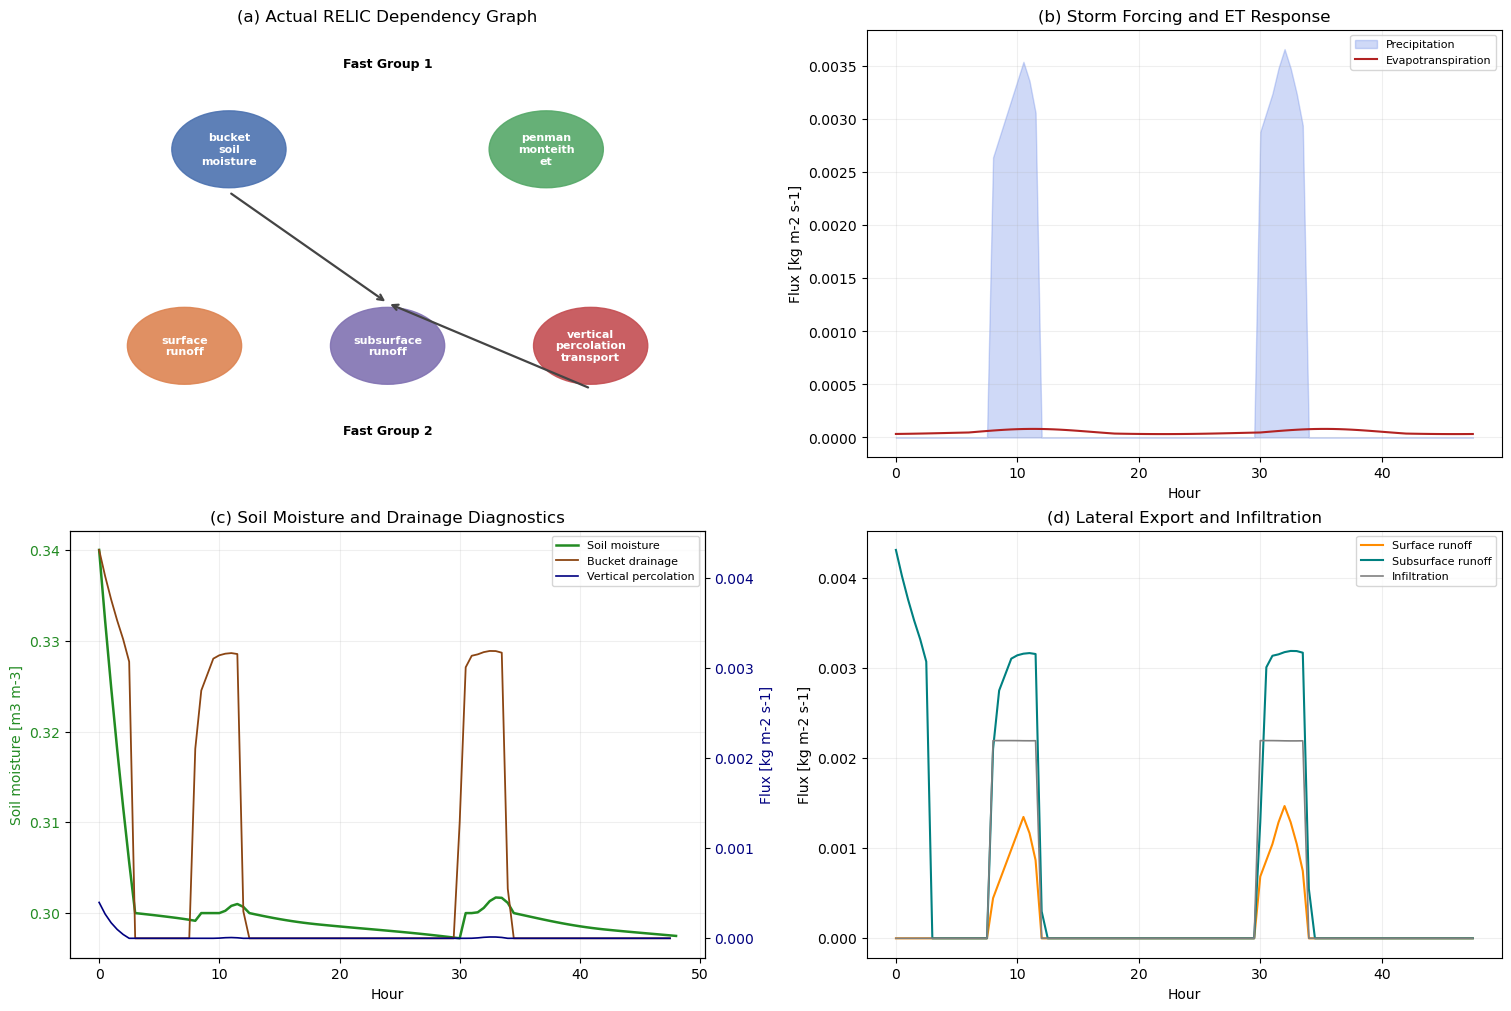

[OK] 48 h fast-process run checked: dt_fast=1800 s, surface_runoff_max=1.468121e-03, subsurface_runoff_max=4.310917e-03, bucket_drainage_max=4.310917e-03, percolation_max=3.983807e-04, soil_moisture_range=(0.297, 0.340)


In [10]:
from IPython.display import display
# References:
# - Manabe, S. (1969). Monthly Weather Review, 97(11), 739-774.
# - Allen, R.G. et al. (1998). FAO Irrigation and Drainage Paper 56.
# - USDA Soil Conservation Service runoff framework.
# - RELIC hydrosphere functors in bucket.py, penman_monteith.py, surface.py, subsurface.py, vertical_percolation.py.
# Mathematical expressions:
# - ET(t) = PenmanMonteithET.forward(state_atmosphere, t, dt).evapotranspiration_flux
# - theta(t + dt) = BucketSoilMoisture.forward(theta, P, ET, t, dt).soil_moisture
# - Q_surface(t) = SurfaceRunoff.forward(theta, P, t, dt).surface_runoff_flux
# - Q_subsurface(t) = SubsurfaceRunoff.forward(theta, drainage_flux, t, dt).subsurface_runoff_flux
# - q_perc(t) = VerticalPercolationTransport.forward(theta, T_soil, t, dt).drainage_flux
# Units: SI state and flux units as listed below; time is in seconds.
# Domain/constraints: Finite declared hydrology inputs; PM dt <= 3600 s; competing closures are probed separately.
# Sign convention: Rain enters the soil; ET, runoff, and drainage are outward-positive fluxes.
# Parameter meanings:
# - dt_fast: fast-process time step [s].
# - precipitation_flux: storm forcing [kg m-2 s-1].
# - net_radiation: available energy for ET [W m-2].
# - vapor_pressure_deficit: atmospheric vapor demand [Pa].
# - soil_moisture: volumetric soil water content [m3 m-3].

dt_fast = 1800.0
n_steps = 96
hours = torch.arange(n_steps, dtype=torch.float32) * (dt_fast / 3600.0)
precipitation_flux_series = torch.zeros(n_steps, dtype=torch.float32)

storm_one = 1.2 * torch.tensor([0.0022, 0.00235, 0.0025, 0.00265, 0.0028, 0.00295, 0.0028, 0.00255], dtype=torch.float32)
storm_two = 1.2 * torch.tensor([0.0024, 0.00255, 0.0027, 0.0029, 0.00305, 0.0029, 0.0027, 0.00245], dtype=torch.float32)
precipitation_flux_series[16:24] = storm_one
precipitation_flux_series[60:68] = storm_two

phase_radiation = 2.0 * torch.pi * (hours - 6.0) / 24.0
phase_temperature = 2.0 * torch.pi * (hours - 4.0) / 24.0
net_radiation_series = 140.0 + 180.0 * torch.clamp(torch.sin(phase_radiation), min=0.0)
air_temperature_series = 289.15 + 6.5 * torch.sin(phase_temperature)
vpd_series = 800.0 + 1400.0 * torch.clamp(torch.sin(phase_radiation), min=0.0)

soil_moisture = torch.tensor(0.340, dtype=torch.float32)
groundwater_storage = torch.tensor(0.0, dtype=torch.float32)

soil_moisture_history = [soil_moisture.detach().clone()]
evapotranspiration_history = []
surface_runoff_history = []
subsurface_runoff_history = []
infiltration_history = []
bucket_drainage_history = []
vertical_percolation_history = []
groundwater_storage_history = [groundwater_storage.detach().clone()]

for step_idx in range(n_steps):
    current_time = float(step_idx) * dt_fast
    precipitation_flux = precipitation_flux_series[step_idx]

    atmosphere_state = {
        "net_radiation": net_radiation_series[step_idx],
        "air_temperature": air_temperature_series[step_idx],
        "wind_speed": torch.tensor(2.2, dtype=torch.float32),
        "atmospheric_pressure": torch.tensor(101325.0, dtype=torch.float32),
        "relative_humidity": torch.tensor(0.60, dtype=torch.float32),
        "vapor_pressure_deficit": vpd_series[step_idx],
        "surface_resistance": torch.tensor(100.0, dtype=torch.float32),
        "stomatal_conductance": torch.tensor(0.01, dtype=torch.float32),
        "canopy_conductance": torch.tensor(0.01, dtype=torch.float32),
        "aerodynamic_resistance": torch.tensor(50.0, dtype=torch.float32),
    }
    penman_updates = penman_monteith_et(atmosphere_state, time=current_time, dt=dt_fast)
    evapotranspiration_flux = unwrap_update(penman_updates["evapotranspiration_flux"]).detach().to(dtype=torch.float32)

    bucket_updates = bucket_soil_moisture(
        {
            "soil_moisture": soil_moisture,
            "precipitation_flux": precipitation_flux,
            "evapotranspiration_flux": evapotranspiration_flux,
            "air_temperature": air_temperature_series[step_idx],
        },
        time=current_time,
        dt=dt_fast,
    )
    soil_moisture = unwrap_update(bucket_updates["soil_moisture"]).detach().to(dtype=torch.float32)
    bucket_drainage_flux = unwrap_update(bucket_updates["drainage_flux"]).detach().to(dtype=torch.float32)

    surface_updates = surface_runoff(
        {
            "soil_moisture": soil_moisture,
            "precipitation_flux": precipitation_flux,
        },
        time=current_time,
        dt=dt_fast,
    )
    surface_runoff_flux = unwrap_update(surface_updates["surface_runoff_flux"]).detach().to(dtype=torch.float32)
    infiltration_flux = unwrap_update(surface_updates["infiltration_flux"]).detach().to(dtype=torch.float32)

    vertical_updates = vertical_percolation_transport(
        {
            "soil_moisture": soil_moisture,
            "soil_temperature": air_temperature_series[step_idx],
        },
        time=current_time,
        dt=dt_fast,
    )
    percolation_flux = unwrap_update(vertical_updates["drainage_flux"]).detach().to(dtype=torch.float32)

    subsurface_updates = subsurface_runoff(
        {
            "soil_moisture": soil_moisture,
            "groundwater_storage": groundwater_storage,
            "drainage_flux": bucket_drainage_flux,
        },
        time=current_time,
        dt=dt_fast,
    )
    groundwater_storage = unwrap_update(subsurface_updates["groundwater_storage"]).detach().to(dtype=torch.float32)
    subsurface_runoff_flux = unwrap_update(subsurface_updates["subsurface_runoff_flux"]).detach().to(dtype=torch.float32)

    soil_moisture_history.append(soil_moisture.detach().clone())
    evapotranspiration_history.append(evapotranspiration_flux.detach().clone())
    surface_runoff_history.append(surface_runoff_flux.detach().clone())
    subsurface_runoff_history.append(subsurface_runoff_flux.detach().clone())
    infiltration_history.append(infiltration_flux.detach().clone())
    bucket_drainage_history.append(bucket_drainage_flux.detach().clone())
    vertical_percolation_history.append(percolation_flux.detach().clone())
    groundwater_storage_history.append(groundwater_storage.detach().clone())

soil_moisture_history = torch.stack(soil_moisture_history)
evapotranspiration_history = torch.stack(evapotranspiration_history)
surface_runoff_history = torch.stack(surface_runoff_history)
subsurface_runoff_history = torch.stack(subsurface_runoff_history)
infiltration_history = torch.stack(infiltration_history)
bucket_drainage_history = torch.stack(bucket_drainage_history)
vertical_percolation_history = torch.stack(vertical_percolation_history)
groundwater_storage_history = torch.stack(groundwater_storage_history)

composition_diagnostics = {
    "dt_fast_seconds": dt_fast,
    "surface_runoff_max": tensor_to_float(torch.max(surface_runoff_history)),
    "subsurface_runoff_max": tensor_to_float(torch.max(subsurface_runoff_history)),
    "bucket_drainage_max": tensor_to_float(torch.max(bucket_drainage_history)),
    "percolation_max": tensor_to_float(torch.max(vertical_percolation_history)),
    "soil_moisture_min": tensor_to_float(torch.min(soil_moisture_history)),
    "soil_moisture_max": tensor_to_float(torch.max(soil_moisture_history)),
    "evapotranspiration_max": tensor_to_float(torch.max(evapotranspiration_history)),
}

state_hours = (torch.arange(n_steps + 1, dtype=torch.float32) * (dt_fast / 3600.0)).tolist()
plot_hours = hours.tolist()

fig, axes = plt.subplots(2, 2, figsize=(15, 10), constrained_layout=True)

ax = axes[0, 0]
node_positions = {
    "bucket_soil_moisture": (0.25, 0.72),
    "penman_monteith_et": (0.75, 0.72),
    "surface_runoff": (0.18, 0.26),
    "subsurface_runoff": (0.50, 0.26),
    "vertical_percolation_transport": (0.82, 0.26),
}
node_colors = {
    "bucket_soil_moisture": "#4C72B0",
    "penman_monteith_et": "#55A868",
    "surface_runoff": "#DD8452",
    "subsurface_runoff": "#8172B2",
    "vertical_percolation_transport": "#C44E52",
}
for node_name, (x_pos, y_pos) in node_positions.items():
    circle = plt.Circle((x_pos, y_pos), 0.09, color=node_colors[node_name], alpha=0.90)
    ax.add_patch(circle)
    label = node_name.replace("_", "\n")
    ax.text(x_pos, y_pos, label, ha="center", va="center", fontsize=8, color="white", fontweight="bold")
for upstream, downstream in [
    ("bucket_soil_moisture", "subsurface_runoff"),
    ("vertical_percolation_transport", "subsurface_runoff"),
]:
    x0, y0 = node_positions[upstream]
    x1, y1 = node_positions[downstream]
    ax.annotate("", xy=(x1, y1 + 0.10), xytext=(x0, y0 - 0.10), arrowprops=dict(arrowstyle="->", lw=1.6, color="#444444"))
ax.text(0.50, 0.92, "Fast Group 1", ha="center", va="center", fontsize=9, fontweight="bold")
ax.text(0.50, 0.06, "Fast Group 2", ha="center", va="center", fontsize=9, fontweight="bold")
ax.set_xlim(0.0, 1.0)
ax.set_ylim(0.0, 1.0)
ax.axis("off")
ax.set_title("(a) Actual RELIC Dependency Graph")

ax = axes[0, 1]
ax.fill_between(plot_hours, [0.0] * n_steps, precipitation_flux_series.detach().tolist(), color="royalblue", alpha=0.25, label="Precipitation")
ax.plot(plot_hours, evapotranspiration_history.detach().tolist(), color="firebrick", lw=1.5, label="Evapotranspiration")
ax.set_xlabel("Hour")
ax.set_ylabel("Flux [kg m-2 s-1]")
ax.set_title("(b) Storm Forcing and ET Response")
ax.legend(fontsize=8)
ax.grid(True, alpha=0.2)

ax = axes[1, 0]
ax.plot(state_hours, soil_moisture_history.detach().tolist(), color="forestgreen", lw=1.8, label="Soil moisture")
ax.set_xlabel("Hour")
ax.set_ylabel("Soil moisture [m3 m-3]", color="forestgreen")
ax.tick_params(axis="y", labelcolor="forestgreen")
ax.grid(True, alpha=0.2)
ax2 = ax.twinx()
ax2.plot(plot_hours, bucket_drainage_history.detach().tolist(), color="saddlebrown", lw=1.3, label="Bucket drainage")
ax2.plot(plot_hours, vertical_percolation_history.detach().tolist(), color="navy", lw=1.2, label="Vertical percolation")
ax2.set_ylabel("Flux [kg m-2 s-1]", color="navy")
ax2.tick_params(axis="y", labelcolor="navy")
lines_left, labels_left = ax.get_legend_handles_labels()
lines_right, labels_right = ax2.get_legend_handles_labels()
ax.legend(lines_left + lines_right, labels_left + labels_right, fontsize=8, loc="upper right")
ax.set_title("(c) Soil Moisture and Drainage Diagnostics")

ax = axes[1, 1]
ax.plot(plot_hours, surface_runoff_history.detach().tolist(), color="darkorange", lw=1.5, label="Surface runoff")
ax.plot(plot_hours, subsurface_runoff_history.detach().tolist(), color="teal", lw=1.5, label="Subsurface runoff")
ax.plot(plot_hours, infiltration_history.detach().tolist(), color="gray", lw=1.2, label="Infiltration")
ax.set_xlabel("Hour")
ax.set_ylabel("Flux [kg m-2 s-1]")
ax.set_title("(d) Lateral Export and Infiltration")
ax.legend(fontsize=8)
ax.grid(True, alpha=0.2)

display(plt.gcf())
plt.close(plt.gcf())
print(
    f"[OK] 48 h fast-process run checked: dt_fast={dt_fast:.0f} s, "
    f"surface_runoff_max={composition_diagnostics['surface_runoff_max']:.6e}, "
    f"subsurface_runoff_max={composition_diagnostics['subsurface_runoff_max']:.6e}, "
    f"bucket_drainage_max={composition_diagnostics['bucket_drainage_max']:.6e}, "
    f"percolation_max={composition_diagnostics['percolation_max']:.6e}, "
    f"soil_moisture_range=({composition_diagnostics['soil_moisture_min']:.3f}, {composition_diagnostics['soil_moisture_max']:.3f})"
)

In [11]:
# References:
# - RELIC architecture overview for fast, medium, and slow execution groups.
# - DependencyGraphResolver for stable ordering and parallel groups.
# Mathematical expressions:
# - t_k = k * dt_fast
# - state(t_{k+1}) = F_fast(state(t_k), forcing(t_k), dt_fast)
# Units: SI state and flux units as listed below; time is in seconds.
# Domain/constraints: Finite declared hydrology inputs; PM dt <= 3600 s; competing closures are probed separately.
# Sign convention: Rain enters the soil; ET, runoff, and drainage are outward-positive fluxes.
# Parameter meanings:
# - dt_fast: fast-process time step [s].
# - composition_diagnostics: summary metrics extracted from the actual RELIC run.

print('Actual RELIC fast-process composition summary')
print('-' * 60)
print(f"dt_fast                : {composition_diagnostics['dt_fast_seconds']:.0f} s")
print(f'execution_order        : {execution_order}')
print(f'parallel_groups        : {groups}')
print(f"surface_runoff_max     : {composition_diagnostics['surface_runoff_max']:.6e}")
print(f"subsurface_runoff_max  : {composition_diagnostics['subsurface_runoff_max']:.6e}")
print(f"bucket_drainage_max    : {composition_diagnostics['bucket_drainage_max']:.6e}")
print(f"percolation_max        : {composition_diagnostics['percolation_max']:.6e}")
print(
    f"soil_moisture_range    : ({composition_diagnostics['soil_moisture_min']:.3f}, "
    f"{composition_diagnostics['soil_moisture_max']:.3f})"
)
print(f"evapotranspiration_max : {composition_diagnostics['evapotranspiration_max']:.6e}")
print('[NOTE] Runoff and drainage diagnostics are non-trivial and finite, but they are not presented as a closed single-step water budget in this tutorial.')

assert composition_diagnostics['dt_fast_seconds'] == 1800.0
assert composition_diagnostics['surface_runoff_max'] > 0.0
assert composition_diagnostics['subsurface_runoff_max'] > 0.0
assert composition_diagnostics['bucket_drainage_max'] > 0.0
assert composition_diagnostics['soil_moisture_max'] > composition_diagnostics['soil_moisture_min']
assert bool(torch.isfinite(surface_runoff_history).all())
assert bool(torch.isfinite(subsurface_runoff_history).all())
assert bool(torch.isfinite(soil_moisture_history).all())
print('\n[OK] Actual RELIC hydrology composition executed with non-trivial dynamics at dt_fast = 1800 s')

Actual RELIC fast-process composition summary
------------------------------------------------------------
dt_fast                : 1800 s
execution_order        : ['bucket_soil_moisture', 'penman_monteith_et', 'vertical_percolation_transport', 'surface_runoff', 'subsurface_runoff']
parallel_groups        : [['bucket_soil_moisture', 'penman_monteith_et', 'vertical_percolation_transport', 'surface_runoff'], ['subsurface_runoff']]
surface_runoff_max     : 1.468121e-03
subsurface_runoff_max  : 4.310917e-03
bucket_drainage_max    : 4.310917e-03
percolation_max        : 3.983807e-04
soil_moisture_range    : (0.297, 0.340)
evapotranspiration_max : 8.066646e-05
[NOTE] Runoff and drainage diagnostics are non-trivial and finite, but they are not presented as a closed single-step water budget in this tutorial.

[OK] Actual RELIC hydrology composition executed with non-trivial dynamics at dt_fast = 1800 s


## 8. Summary

- The real resolver verifies the five-node graph, its two optional same-step
  edges, and its two dependency layers.
- Scientific outputs come from actual hydrology kernels with explicit PM
  resistance selection, pressure in Pa, and a 1800 s interval within the
  hourly soil-heat-flux validity domain.
- The local soil-moisture delta is a notebook diagnostic, not the retired
  `soil_moisture_change` state variable.
- These standalone response probes do not prove a closed combined water budget
  or successful registration of the five competing closures. A production
  simulation must select noncompeting state and flux owners and let StateManager
  commit their typed updates.
